# ECON 5200 Final Project: Consulting Report

**A causal question a client would pay to have answered, a design you can defend under attack, a tool that lets them
explore counterfactuals, and a recommendation with its uncertainty attached.**

This notebook is the spine of the project. Each milestone hands in part of it:

| Hand-in | Due | Parts |
|---|---|---|
| Milestone 1: Proposal + EDA (10 pts) | Mon 23 Nov | Part 2, plus the two-page proposal from the **Proposal Template (Word)** |
| Milestone 2: Analysis + Threats (20 pts) | Thu 3 Dec | Part 3, a first draft of Part 4, a Part 5 prototype with one working what-if input |
| Final Project (70 pts) | see Canvas | all of it, with Part 1 written last |

Every number in your report must be printed by a cell in this notebook. If the code does not print it, the report
cannot use it.

---

## Part 0: Setup

In [1]:
# Colab has pandas, numpy, statsmodels, scikit-learn and matplotlib already.
# Install only what your design needs, then restart the runtime once:
# !pip -q install linearmodels        # IV (2SLS) and panel fixed effects
# !pip -q install rdrobust rddensity   # RD
# !pip -q install doubleml             # DML

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent   # repo root
RAW = ROOT / "data" / "raw"
STATE_COL, LAUNCH_COL = "State", "Online Launch"
CUTOFF_MONTH = 6          # launch counts in year y if month <= 6, else y+1
LAST_DATA_YEAR = 2025     # last Q4 snapshot in the NY Fed file
START_YEAR = 2012
PRE_YEARS = range(2012, 2019)   # before the first cohort (2019)
RETAIL_ONLY = ["MS", "MT", "NE", "NM", "ND", "SD", "WA", "WI"]

---
## Part 1: Executive Summary

Write this **last**. Situation, Complication, Resolution, then the recommendation with its interval and the
assumption it rests on. The rubric looks for all three in the summary itself.

> **We estimate that [treatment] changes [outcome] by [X] [units] (95% CI [a, b]).**
>
> **Situation:** ___
> **Complication:** ___
> **Resolution:** ___
>
> **We recommend [action] because [reason]. At the bottom of the interval, [what the client should still do].**
>
> **The assumption that would overturn this:** ___

---
## Part 2: The Decision, the Design, and the Data (Milestone 1)

### Research design

These lines are the proposal's page 1. The **Proposal Template (Word)** on Canvas has the same headings.

- **Client and decision:** who acts on the answer, and what they will do differently.
- **Decides it:** the effect size at which the decision changes. Write it before you estimate anything.
- **Causal question:** does [treatment] cause [outcome], for whom, by how much?
- **Why prediction is not enough:** the comparison in your data that would mislead the client.
- **Design and estimand:** DiD, IV, RD or DML, and whose effect it recovers (average, on the treated, compliers,
  at the cutoff). DML is Topic 24, taught Wed 9 Dec, after both milestones.
- **Who is treated:** the unit of treatment, and how many treated units your data have.
- **The comparison:** treated against what.
- **Key assumption:** parallel trends / exclusion and relevance / no manipulation at the cutoff / conditional
  independence given these controls.
- **How you will check it:** the test that could fail.
- **The threat you worry about most:** which variable, through which path, and the sign of the bias it would cause.

## Part 2: Design and EDA
- **Client and decision:** a credit card issuer deciding whether to tighten underwriting (higher score cutoffs, lower starting limits) in states that launch mobile sports betting.
- **Decides it:** tighten if launch raises the share of card balances 90+ days delinquent by at least 0.5 pp (about 7% of the 7.6% pre-period mean); below that, normal risk-based pricing absorbs it.
- **Causal question:** does launching legal mobile sports betting raise credit card delinquency in the launching state, and by how many pp?
- **Why prediction is not enough:** launching states differ from non-launching ones (larger, more urban), and launches coincided with the COVID drop in delinquency; comparing delinquency across states, or before vs after launch, mixes these with any betting effect.
- **Design and estimand:** staggered DiD, Callaway-Sant'Anna style, recovering the ATT (the average effect in states that launched), by cohort and event time; TWFE with a Goodman-Bacon decomposition as a diagnostic.
- **Who is treated:** states (unit = state-year); 30 states incl. DC launched mobile betting, in 6 cohorts from 2019 to 2024 (a launch counts in year y if it happened by June, else y+1).
- **The comparison:** 11 never-legal states plus states not yet launched; 8 retail-only states kept as controls and dropped in a robustness check; NV dropped (always treated), MO untreated through 2025.
- **Key assumption:** parallel trends: absent launch, delinquency in launching states would have moved like in comparison states; no anticipation before launch.
- **How you will check it:** event-study pre-period coefficients should be jointly zero; the check fails if launching states were already diverging before launch.
- **The threat you worry about most:** COVID relief (stimulus, forbearance) in 2020–21, when 9 states launched; if launching states got more relief, their delinquency fell for reasons unrelated to betting, biasing the estimate downward and hiding harm.

Cell 2.1: Load the data (1/4): state name -> code

In [3]:
NAME_TO_CODE = {
    "alabama": "AL", "alaska": "AK", "arizona": "AZ", "arkansas": "AR", "california": "CA",
    "colorado": "CO", "connecticut": "CT", "delaware": "DE", "district of columbia": "DC",
    "washington dc": "DC", "florida": "FL", "georgia": "GA", "hawaii": "HI", "idaho": "ID",
    "illinois": "IL", "indiana": "IN", "iowa": "IA", "kansas": "KS", "kentucky": "KY",
    "louisiana": "LA", "maine": "ME", "maryland": "MD", "massachusetts": "MA", "michigan": "MI",
    "minnesota": "MN", "mississippi": "MS", "missouri": "MO", "montana": "MT", "nebraska": "NE",
    "nevada": "NV", "new hampshire": "NH", "new jersey": "NJ", "new mexico": "NM",
    "new york": "NY", "north carolina": "NC", "north dakota": "ND", "ohio": "OH",
    "oklahoma": "OK", "oregon": "OR", "pennsylvania": "PA", "rhode island": "RI",
    "south carolina": "SC", "south dakota": "SD", "tennessee": "TN", "texas": "TX",
    "utah": "UT", "vermont": "VT", "virginia": "VA", "washington": "WA",
    "west virginia": "WV", "wisconsin": "WI", "wyoming": "WY",
}
CODES = set(NAME_TO_CODE.values())

def to_code(name):
    s = str(name).strip()
    if s.upper() in CODES:
        return s.upper()
    key = re.sub(r"\s+", " ", re.sub(r"[.,]", " ", s.lower())).strip()
    return NAME_TO_CODE.get(key)

Cell 2.2: Load the data (2/4): NY Fed outcome, wide -> long

In [4]:
cc = pd.read_excel(RAW / "area_report_by_year.xlsx", sheet_name="creditcard_delinq", header=8)
cc = cc.rename(columns={cc.columns[0]: "state"})
cc["state"] = cc["state"].astype(str).str.strip()
cc = cc[cc["state"].isin(CODES)]          # drops PR, allUS and footnote rows

year_cols = {c: int(m.group()) for c in cc.columns if (m := re.search(r"(19|20)\d{2}", str(c)))}
cc = cc[["state", *year_cols]].melt(id_vars="state", var_name="col", value_name="cc_delinq90")
cc["year"] = cc["col"].map(year_cols)
cc["cc_delinq90"] = pd.to_numeric(cc["cc_delinq90"], errors="coerce")
cc = cc[["state", "year", "cc_delinq90"]]
print(cc["state"].nunique(), "states,", cc["year"].min(), "to", cc["year"].max())

51 states, 2003 to 2025


Cell 2.3: Load the data (3/4): launch dates -> first_treat_year and group

In [ ]:
def parse_launch(x):
    if pd.isna(x):
        return pd.NaT
    if isinstance(x, (int, float, np.integer, np.floating)):   # bare year, e.g. 2010
        return pd.Timestamp(int(x), 1, 1)
    return pd.to_datetime(str(x).strip(), errors="coerce")       # text -> NaT

launch = pd.read_excel(RAW / "launch_data.xlsx")
launch["code"] = launch[STATE_COL].map(to_code)
launch["launch"] = launch[LAUNCH_COL].map(parse_launch)
print("Unmatched names:", launch.loc[launch["code"].isna(), STATE_COL].tolist())
print("Read as 'no launch':",
      launch.loc[launch["launch"].isna() & launch[LAUNCH_COL].notna(), LAUNCH_COL].unique().tolist())

yr, mo = launch["launch"].dt.year, launch["launch"].dt.month
launch["first_treat_year"] = np.where(mo <= CUTOFF_MONTH, yr, yr + 1)
launch["group"] = np.select(
    [yr < 2018,                                    # Nevada: always treated
     launch["first_treat_year"] <= LAST_DATA_YEAR,
     launch["first_treat_year"] > LAST_DATA_YEAR,  # Missouri: untreated in sample
     launch["code"].isin(RETAIL_ONLY)],
    ["always_treated", "treated", "not_yet_in_data", "retail_only"],
    default="never",
)
launch = launch[["code", "launch", "first_treat_year", "group"]].rename(columns={"code": "state"})

Unmatched names: []
Read as 'no launch': ['Not available']


Cell 2.4: Load the data (4/4): state-by-year panel

In [6]:
panel = cc.merge(launch, on="state", how="left", validate="m:1")
assert panel["group"].notna().all(), "a state is missing from the launch file"
panel = panel[(panel["year"] >= START_YEAR) & (panel["group"] != "always_treated")]
panel["post"] = (panel["year"] >= panel["first_treat_year"]).astype(int)
panel = panel.reset_index(drop=True)
print(panel.shape)
panel.head()

(700, 7)


,state,year,cc_delinq90,launch,first_treat_year,group,post
0,AK,2012,5.22,NaT,NaN,never,0
1,AL,2012,9.57,NaT,NaN,never,0
2,AR,2012,9.10,2022-03-01,2022.0,treated,0
3,AZ,2012,13.27,2021-09-01,2022.0,treated,0
4,CA,2012,13.26,NaT,NaN,never,0


Cell 2.5: Missing values and the sample rule


In [7]:
print(panel.isna().sum())   # launch / first_treat_year are NaN for untreated states by design
print(panel.groupby("group")["state"].nunique())
print(panel.groupby("first_treat_year")["state"].nunique())   # cohort sizes
# Sample rule:
# - dropped PR and the allUS row (not states)
# - dropped NV: mobile betting since 2010, so treated for the whole sample
# - years 2012-2025, so the pre-period starts after the Great Recession
# - MO launched Dec 2025: untreated through 2025
# - retail-only states kept as controls; dropped in a robustness check

state                 0
year                  0
cc_delinq90           0
launch              266
first_treat_year    266
group                 0
post                  0
dtype: int64
group
never              11
not_yet_in_data     1
retail_only         8
treated            30
Name: state, dtype: int64
first_treat_year
2019.0    2
2020.0    9
2021.0    3
2022.0    6
2023.0    4
2024.0    6
2026.0    1
Name: state, dtype: int64


Cell 2.6: Balance: pre-period 2012-2018, one row per state, treated vs never-legal

In [8]:
def balance_table(data, group, cols):
    """Means by group, the difference, and the standardised difference (difference / pooled SD)."""
    g1, g0 = data[data[group] == 1], data[data[group] == 0]
    rows = []
    for c in cols:
        sd = np.sqrt((g1[c].var() + g0[c].var()) / 2)
        rows.append({"variable": c, "treated": g1[c].mean(), "comparison": g0[c].mean(),
                     "difference": g1[c].mean() - g0[c].mean(),
                     "std. difference": (g1[c].mean() - g0[c].mean()) / sd if sd > 0 else np.nan})
    out = pd.DataFrame(rows).set_index("variable")
    out.loc["N"] = [len(g1), len(g0), np.nan, np.nan]
    return out.round(3)

pre = panel[panel["year"].isin(PRE_YEARS) & panel["group"].isin(["treated", "never"])]
wide = pre.pivot(index="state", columns="year", values="cc_delinq90")
states = pd.DataFrame({
    "treated": (pre.groupby("state")["group"].first() == "treated").astype(int),
    "cc_delinq90_pre": wide.mean(axis=1),
    "cc_change_2012_18": wide[2018] - wide[2012],
})
balance_table(states, "treated", ["cc_delinq90_pre", "cc_change_2012_18"])

,treated,comparison,difference,std. difference
variable,,,,
cc_delinq90_pre,7.569,7.591,-0.022,-0.017
cc_change_2012_18,-2.303,-2.501,0.198,0.123
N,30.000,11.000,NaN,NaN


Cell 2.7: Figure 1: delinquency by state group over time

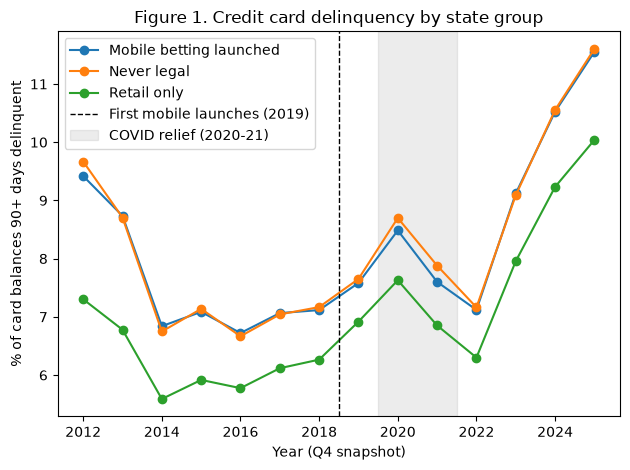

In [9]:
labels = {"treated": "Mobile betting launched", "never": "Never legal", "retail_only": "Retail only"}
means = panel[panel["group"].isin(labels)].groupby(["year", "group"])["cc_delinq90"].mean().unstack()
for g, lab in labels.items():
    plt.plot(means.index, means[g], marker="o", label=lab)
plt.axvline(2018.5, color="black", ls="--", lw=1, label="First mobile launches (2019)")
plt.axvspan(2019.5, 2021.5, color="grey", alpha=0.15, label="COVID relief (2020-21)")
plt.title("Figure 1. Credit card delinquency by state group")
plt.xlabel("Year (Q4 snapshot)"); plt.ylabel("% of card balances 90+ days delinquent")
plt.legend(); plt.tight_layout()
plt.savefig(ROOT / "proposal" / "fig1.png", dpi=200); plt.show()

Cell 2.8: Key number: naive raw DiD, 2020 cohort (largest) vs never-legal

In [10]:
def raw_did(cohort, k=3):
    t, c = panel[panel["first_treat_year"] == cohort], panel[panel["group"] == "never"]
    m = lambda df, ys: df[df["year"].isin(ys)]["cc_delinq90"].mean()
    pre_y, post_y = range(cohort - k, cohort), range(cohort, cohort + k)
    return (m(t, post_y) - m(t, pre_y)) - (m(c, post_y) - m(c, pre_y))

print(f"Raw DiD, 2020 cohort: {raw_did(2020):.2f} pp")

Raw DiD, 2020 cohort: -0.02 pp


**Key EDA finding (one sentence, with a number this notebook printed):** Before any launches (2012–18), launching and never-legal states had nearly identical credit card delinquency (7.57% vs 7.59%, std. diff. −0.02) and similar declines (−2.30 vs −2.50 pp), and a naive DiD for the 2020 cohort is essentially zero (−0.02 pp).

**A concern the design will have to handle:** COVID relief pushed card delinquency down during the COVID years (2020–21), exactly when the largest cohort launched. Year effects absorb the nationwide part, but if launching states received greater relief, their delinquency would have fallen more for reasons unrelated to betting. This would bias the estimate downward and hide any harm, so a robustness check will exclude 2020–21.

---
## Part 3: Analysis (Milestone 2)

### 3a. The naive estimate

The comparison a client's own analyst would run first. You expect it to be biased; say which way, and why.

In [11]:
# naive = smf.ols("outcome ~ treatment", data=df).fit(cov_type="HC1")
# print(naive.params["treatment"], naive.bse["treatment"])

**Why the naive estimate is biased, and in which direction:** ___

### 3b. The causal estimate

Keep the one cell that matches your design and delete the other three. Each reports the estimate, its standard
error and the diagnostic its design must pass.

In [12]:
# --- DiD: two-way fixed effects, standard errors clustered by the unit that was treated ---
# did = smf.ols("outcome ~ treated_post + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# est, se = did.params["treated_post"], did.bse["treated_post"]
#
# Diagnostic, an event study: one coefficient per period relative to treatment, the period before omitted.
# Pre-period coefficients near zero support parallel trends; they cannot prove it.
# es = smf.ols("outcome ~ C(rel_time, Treatment(reference=-1)) + C(unit) + C(period)", data=df).fit(
#     cov_type="cluster", cov_kwds={"groups": df["unit"]})
# With few treated clusters (under about 20), say so and report a wild cluster bootstrap p-value as well.

In [13]:
# --- IV: two-stage least squares, with the first stage reported ---
# from linearmodels.iv import IV2SLS
# iv = IV2SLS.from_formula("outcome ~ 1 + control_1 + [treatment ~ instrument]", data=df).fit(cov_type="robust")
# est, se = iv.params["treatment"], iv.std_errors["treatment"]
# print(iv.first_stage)          # the first-stage F: below 10 is weak, and the 2SLS interval cannot be trusted
# The estimate is the effect for compliers, the units the instrument moved: say who they are.

In [14]:
# --- RD: local linear, the bandwidth chosen by rdrobust, the effect at the cutoff ---
# from rdrobust import rdrobust
# from rddensity import rddensity
# rd = rdrobust(y=df["outcome"], x=df["running"], c=CUTOFF)
# est, se = rd.coef.loc["Conventional", "Coeff"], rd.se.loc["Conventional", "Std. Err."]
# print(rd)                      # report the bandwidth with the estimate
# print(rd.ci.loc["Robust"])     # the bias-corrected interval: report this one, beside est
# print(rddensity(X=df["running"].to_numpy(), c=CUTOFF).test)   # manipulation at the cutoff
# rdrobust reports right minus left: if treatment is BELOW the cutoff, use running = CUTOFF - x.

In [15]:
# --- DML: partially linear model, cross-fitted, five folds (Topic 24, taught Wed 9 Dec: read Chapter 24 ahead) ---
# from doubleml import DoubleMLData, DoubleMLPLR
# from sklearn.ensemble import RandomForestRegressor
# controls = ["control_1", "control_2", "control_3"]
# dml_data = DoubleMLData(df, y_col="outcome", d_cols="treatment", x_cols=controls)
# learner = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE)
# dml = DoubleMLPLR(dml_data, ml_l=learner, ml_m=learner, n_folds=5)
# dml.fit()
# est, se = dml.coef[0], dml.se[0]
# Diagnostic: overlap. If some units are almost certainly treated or untreated given the controls, the
# estimate leans on extrapolation; plot the cross-fitted treatment predictions by treatment group.

In [16]:
# --- The estimate, its interval and N, in one line the report can quote ---
# ci_low, ci_high = est - 1.96 * se, est + 1.96 * se
# print(f"estimate {est:+.4f} (SE {se:.4f}), 95% CI [{ci_low:+.4f}, {ci_high:+.4f}], N = {len(df):,}")

### 3c. Naive against causal

> The naive estimate is [X]; the causal estimate is [Y]. The gap of [Y - X] is what [the confounder / selection]
> was doing, and its sign matches (or does not match) the direction predicted in 3a.

### 3d. A robustness check that could have overturned the result

The mission asks for at least one check that could have gone the other way. Pick by design:

| Design | A check that can fail |
|---|---|
| DiD | a placebo treatment date in the pre-period; an outcome the policy cannot affect; drop each treated unit in turn |
| IV | a second instrument, alone; the reduced form; an Anderson–Rubin interval if the first stage is weak |
| RD | half and double the bandwidth; a donut that drops the units nearest the cutoff; placebo cutoffs |
| DML | a different learner for the nuisances; a different control set; trimming units with extreme treatment predictions |

For each: what you changed, what you found (the number beside the baseline), and **what it implies** for the claim.

In [17]:
# --- Robustness: your check here ---

### 3e. Sensitivity bound

How strong would an unobserved confounder have to be to erase the estimate, measured against one you observed?
For a regression-based estimate (DiD, DML's final stage, OLS with controls) the **robustness value** answers it
(Cinelli and Hazlett 2020, *JRSS-B* 82(1)). It is the share of the remaining variance of both the treatment and the
outcome that a confounder would have to explain to bring the estimate to zero. Compare it with the strongest control
you have: if no confounder as strong as that control could erase the estimate, say so; if one could, say that.

For RD and IV the equivalent question is about the design's own assumption: how far would the outcome have to jump
at the cutoff for other reasons, or how large a direct effect of the instrument, to explain the estimate?

In [18]:
def robustness_value(t_stat, dof, q=1.0):
    """Cinelli and Hazlett's RV_q: the partial R-squared a confounder needs with BOTH treatment and outcome to
    move the estimate by 100*q percent (q = 1 brings it to zero)."""
    f = q * abs(t_stat) / np.sqrt(dof)
    return 0.5 * (np.sqrt(f**4 + 4 * f**2) - f**2)


def partial_r2(t_stat, dof):
    """A regressor's partial R-squared, recovered from its t-statistic."""
    return t_stat**2 / (t_stat**2 + dof)


# The paper's own example (Darfur, t = 4.18 on 783 degrees of freedom) gives RV = 13.9%:
print(f"check against Cinelli and Hazlett's example: RV = {robustness_value(4.18, 783):.1%} (paper: 13.9%)")

# Your estimate, from a regression with your controls (fit.tvalues / fit.df_resid):
# rv = robustness_value(fit.tvalues["treatment"], fit.df_resid)
# Benchmark: your strongest control's partial R-squared with the outcome, and with the treatment.
# out_fit = smf.ols("outcome ~ treatment + control_1 + control_2", data=df).fit()
# trt_fit = smf.ols("treatment ~ control_1 + control_2", data=df).fit()
# bench_y = partial_r2(out_fit.tvalues["control_1"], out_fit.df_resid)
# bench_d = partial_r2(trt_fit.tvalues["control_1"], trt_fit.df_resid)
# print(f"RV = {rv:.1%}; control_1 explains {bench_y:.1%} of the outcome and {bench_d:.1%} of the treatment")

check against Cinelli and Hazlett's example: RV = 13.9% (paper: 13.9%)


---
## Part 4: Threats to Identification (draft at Milestone 2)

Not "there may be confounding": **which** variable, through **which** path, and **which way** it moves your estimate.
A threat you cannot address is still worth naming. An unnamed one is what the client's analyst will find.

| Threat | Path | Sign of the bias | What I did about it |
|---|---|---|---|
| ___ | ___ → treatment, ___ → outcome | too large / too small / unknown, and why | ___ |
| ___ | ___ | ___ | ___ |
| ___ | ___ | ___ | ___ |

**What I cannot rule out, and what it means for how the client should read the estimate** (an upper bound, a lower
bound, or suggestive only): ___

Milestone 2 asks for at least 500 words across the table and this paragraph.

---
## Part 5: The Streamlit Dashboard

The app must not fit a model. Your deliverable is a causal estimate, a number and a standard error, so write them
to `results.json` here and let the app do arithmetic. The Canvas page **Streamlit Dashboard and Deployment** has
the deployment steps, `requirements.txt`, and every deploy error by its message.

A what-if is an input **the client controls** and an output that is a counterfactual with its interval:
how many units the policy reaches, what it costs, how much hidden bias they are willing to assume. Scaling the
effect beyond the range of treatment in your data is an extrapolation; if your app offers it, the page must say so.

In [19]:
# --- results.json: everything the app needs, printed by this notebook ---
# results = {
#     "question": "Does [treatment] change [outcome]?",
#     "design": "DiD", "estimand": "effect on the treated",
#     "estimate": float(est), "se": float(se), "n": int(len(df)),
#     "unit": "[outcome units] per [treated unit]",
#     "baseline": float(df.loc[df["treatment"] == 0, "outcome"].mean()),   # continuous treatment: df["outcome"].mean()
#     "robustness_value": float(rv),
# }
# with open("results.json", "w") as f:
#     json.dump(results, f, indent=1)
# print(json.dumps(results, indent=1))

In [20]:
app_py = """
import json

import numpy as np
import plotly.graph_objects as go
import streamlit as st

r = json.load(open("results.json"))
st.set_page_config(page_title="Consulting Report", layout="wide")
st.title(r["question"])
st.caption(f"{r['design']}, {r['estimand']}, N = {r['n']:,}")

st.sidebar.header("Your scenario")
reach = st.sidebar.number_input("Units the policy would reach", min_value=1, value=100, step=10)
cost = st.sidebar.number_input("Cost per unit reached", min_value=0.0, value=0.0, step=1.0)
bias = st.sidebar.slider("Hidden bias you are willing to assume (share of the estimate)", -1.0, 1.0, 0.0, 0.05,
                         help="0 trusts the design. 0.5 assumes half the estimate is confounding.")

est = r["estimate"] * (1 - bias)
se = r["se"]
total, total_lo, total_hi = est * reach, (est - 1.96 * se) * reach, (est + 1.96 * se) * reach

c1, c2, c3 = st.columns(3)
c1.metric("Effect per unit", f"{est:+.3f}", help=r["unit"])
c2.metric("Total effect, 95% CI", f"{total:+,.1f}", f"[{total_lo:+,.1f}, {total_hi:+,.1f}]", delta_color="off")
c3.metric("Total cost", f"{cost * reach:,.0f}")

st.markdown(f"If the policy reaches **{reach:,}** units, the estimated total change is **{total:+,.1f}** "
            f"(95% CI {total_lo:+,.1f} to {total_hi:+,.1f}), assuming {bias:.0%} of the estimate is hidden bias.")

grid = np.linspace(-1, 1, 81)
mid = r["estimate"] * (1 - grid)
fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=mid + 1.96 * se, mode="lines", line=dict(width=0), showlegend=False))
fig.add_trace(go.Scatter(x=grid, y=mid - 1.96 * se, mode="lines", line=dict(width=0), fill="tonexty",
                         fillcolor="rgba(46,109,180,0.2)", name="95% CI"))
fig.add_trace(go.Scatter(x=grid, y=mid, mode="lines", line=dict(color="#2E6DB4"), name="Effect per unit"))
fig.add_hline(y=0, line_dash="dot", line_color="grey")
fig.add_vline(x=bias, line_dash="dash", line_color="#b03a2e")
fig.update_layout(xaxis_title="Assumed hidden bias (share of the estimate)", yaxis_title=r["unit"],
                  template="plotly_white")
st.plotly_chart(fig)
"""

# Uncomment to write it, then commit app.py, results.json and requirements.txt to your repository:
# with open("app.py", "w") as f:
#     f.write(app_py)
print("app.py template ready: uncomment the two lines above to write it.")

app.py template ready: uncomment the two lines above to write it.


**The `.py` module.** The repository needs a module, not only notebooks. Move the functions you call more than once
(loading and cleaning, the estimate, the robustness check) into `src/analysis.py`, import them here, and let the
README name the one command that reproduces `results.json`.

---
## Part 6: The Five-Minute Video

Exactly three things. Five minutes is a ceiling, not a target.

| | What it is | Yours |
|---|---|---|
| **One visual** | the figure that makes the causal claim believable (Figure 1 or the event study, usually) | ___ |
| **One causal claim** | the estimate, its unit and interval, and the assumption under it, in one sentence | ___ |
| **One recommendation** | what the client should do, and what they should still do at the bottom of the interval | ___ |

### Prepare for the public Q&A

Classmates will open GitHub Issues on your repository. Write your answers to these before they ask:

| They will ask | Your answer |
|---|---|
| "How do you know this is causal?" | ___ |
| "What is the strongest threat, and which way does it bias you?" | ___ |
| "Would this hold for a different population or time?" | ___ |
| "Is the effect big enough to act on?" | ___ |

---
## Part 7: AI Methodology Appendix (P.R.I.M.E.)

At least three entries, each through the five steps: **P**rep, **R**equest, **I**terate, **M**echanism Check,
**E**valuate. Hand it in as a PDF with the report.

### Entry 1: Coding the mobile launch dates (treatment timing)

- **Prep:** I needed a first-treatment year for every state. I had built `launch_data.xlsx` (state, status,
  online launch date, minimum age) from the OutKick state-by-state guide, after another AI chat suggested
  sources (AGA tracker, OutKick). That transcript was lost, so those prompts are paraphrased, not exact.
  I knew a plain TWFE is biased under staggered timing, so the cohort coding had to be right.
- **Request:** In Claude Code I asked it to check and organise my data folder ("this good for data maybe try
  to organize if you can"), then to review the loading code ("is my code fine").
- **Iterate:** It flagged coding decisions in the launch file: Nevada listed as 2010 (treated before the
  sample starts), the 8 retail-only states, December launches (Missouri 2025, Delaware 2023) against a Q4
  snapshot, Florida's 2021 launch and halt, full state names vs the NY Fed's two-letter codes, and a launch
  column mixing dates, text and a bare year. It suggested an October cutoff for the treatment year. In the
  code review it found that my column names ("state", "mobile_launch") did not match the file ("State",
  "Online Launch"), which raised a KeyError.
- **Mechanism Check:** After fixing the column names, the notebook prints "Unmatched names: []" and shows that
  only "Not available" was read as no launch. The cohort sizes it prints (2, 9, 3, 6, 4, 6 for 2019–2024,
  Missouri in 2026) match the dates in my file.
- **Evaluate:** I accepted dropping Nevada and treating Missouri as untreated through 2025. I rejected the
  October cutoff and used June instead, because 90+ day delinquency needs time to show up in the Q4 snapshot.
  I kept October as a robustness check. I kept the retail-only states as controls, dropping them in a
  robustness check. I wrote the parsing and grouping code myself.

### Entry 2: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

### Entry 3: [task]

- **Prep:** ___
- **Request:** ___
- **Iterate:** ___
- **Mechanism Check:** ___
- **Evaluate:** ___

> Graded on judgment, not volume. One entry where the model was wrong and you caught it at the Mechanism Check is
> worth more than three where you pasted and moved on.